## Library

In [ ]:
# import os
# import glob
# import cv2
# import numpy as np
# import pandas as pd
# from collections import Counter
# import matplotlib.pyplot as plt
# import seaborn as sns

## Connect to G.Drive

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

# print("koneksi ke g.drive berhasil")

## Dataset

In [ ]:
DATASET_DIR = "/content/drive/MyDrive/semRAUT"

## Data Deskriptif

In [ ]:
print("=== 1. DATA DESKRIPTIF ===")
subsets = ['train', 'valid', 'test']
classes = ['center', 'down', 'left', 'right', 'up']
total_images_all = 0

for subset in subsets:
    subset_total = 0
    for c in classes:
        # Path mengarah ke: DATASET_DIR / subset / class / (berisi gambar langsung atau folder images)
        # Sesuai struktur roboflow: train/center/gambar.jpg atau train/center/images/
        img_folder_1 = os.path.join(DATASET_DIR, subset, c)
        img_folder_2 = os.path.join(DATASET_DIR, subset, c, 'images')

        target_folder = img_folder_2 if os.path.exists(img_folder_2) else img_folder_1

        if os.path.exists(target_folder):
            images = glob.glob(os.path.join(target_folder, '*.*'))
            subset_total += len(images)

    print(f"Jumlah gambar di subset '{subset}': {subset_total}")
    total_images_all += subset_total

print(f"Total keseluruhan gambar: {total_images_all}\n")

=== 1. DATA DESKRIPTIF ===
Jumlah gambar di subset 'train': 525
Jumlah gambar di subset 'valid': 50
Jumlah gambar di subset 'test': 25
Total keseluruhan gambar: 600



## Distribusi Class

In [ ]:
print("=== 2. DISTRIBUSI KELAS ===")
# Roboflow umumnya menyimpan label dalam format folder (klasifikasi) atau file teks (YOLO)
# Berikut pengecekan jika menggunakan folder klasifikasi per kelas
for subset in subsets:
    subset_dir = os.path.join(DATASET_DIR, subset)
    if os.path.exists(subset_dir):
        classes = [d for d in os.listdir(subset_dir) if os.path.isdir(os.path.join(subset_dir, d)) and d != 'images']
        if classes:
            print(f"Distribusi kelas di {subset}:")
            for c in classes:
                count = len(os.listdir(os.path.join(subset_dir, c)))
                print(f" - {c}: {count} gambar")
        else:
            print(f"Subset {subset} menggunakan format non-folder kelas (misal YOLO/COCO).")

=== 2. DISTRIBUSI KELAS ===
Distribusi kelas di train:
 - down: 105 gambar
 - left: 105 gambar
 - center: 105 gambar
 - up: 105 gambar
 - right: 105 gambar
Distribusi kelas di valid:
 - left: 10 gambar
 - down: 10 gambar
 - center: 10 gambar
 - right: 10 gambar
 - up: 10 gambar
Distribusi kelas di test:
 - up: 5 gambar
 - center: 5 gambar
 - left: 5 gambar
 - down: 5 gambar
 - right: 5 gambar


## Missing Image/ Label

In [ ]:
print("\n=== 3. PENGECEKAN MISSING IMAGE / LABEL ===")
# Memastikan setiap gambar memiliki pasangan label (jika format YOLO/Detection)
img_exts = ['*.jpg', '*.png', '*.jpeg', '*.JPG', '*.JPEG']
for subset in subsets:
    img_dir = os.path.join(DATASET_DIR, subset, 'images')
    lbl_dir = os.path.join(DATASET_DIR, subset, 'labels')

    if os.path.exists(img_dir) and os.path.exists(lbl_dir):
        imgs = set([os.path.splitext(f)[0] for f in os.listdir(img_dir)])
        lbls = set([os.path.splitext(f)[0] for f in os.listdir(lbl_dir)])

        missing_labels = imgs - lbls
        missing_images = lbls - imgs
        print(f"[{subset}] Gambar tanpa label: {len(missing_labels)}")
        print(f"[{subset}] Label tanpa gambar: {len(missing_images)}")
    else:
        print(f"[{subset}] Struktur folder labels/images terpisah tidak ditemukan (mungkin format klasifikasi murni).")


=== 3. PENGECEKAN MISSING IMAGE / LABEL ===
[train] Struktur folder labels/images terpisah tidak ditemukan (mungkin format klasifikasi murni).
[valid] Struktur folder labels/images terpisah tidak ditemukan (mungkin format klasifikasi murni).
[test] Struktur folder labels/images terpisah tidak ditemukan (mungkin format klasifikasi murni).


## Cek Duplikat

In [ ]:
print("=== 4. PENGECEKAN DUPLIKAT DATA (DENGAN INFORMASI LETAK FILE) ===")
import hashlib

def check_duplicates_with_path(directory):
    hashes = {}
    duplicates = []

    for root, _, files in (w for s in ['train', 'valid', 'test'] for w in os.walk(os.path.join(directory, s))):
        for f in files:
            if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                path = os.path.join(root, f)
                try:
                    with open(path, 'rb') as file:
                        file_hash = hashlib.md5(file.read()).hexdigest()

                        # Jika hash sudah ada, berarti file ini duplikat dari file lain
                        if file_hash in hashes:
                            duplicates.append({
                                'duplicate_file': path,
                                'original_file': hashes[file_hash]
                            })
                        else:
                            hashes[file_hash] = path
                except Exception as e:
                    print(f"Gagal membaca file {path}: {e}")

    return duplicates

duplicate_list = check_duplicates_with_path(DATASET_DIR)

print(f"Total file duplikat terdeteksi: {len(duplicate_list)}\n")

if duplicate_list:
    print("Daftar file duplikat dan lokasi aslinya:")
    for idx, item in enumerate(duplicate_list, 1):
        print(f"{idx}. File duplikat : {item['duplicate_file']}")
        print(   f"   Sama dengan  : {item['original_file']}\n")
else:
    print("Tidak ditemukan file yang duplikat.")

=== 4. PENGECEKAN DUPLIKAT DATA (DENGAN INFORMASI LETAK FILE) ===
Total file duplikat terdeteksi: 6

Daftar file duplikat dan lokasi aslinya:
1. File duplikat : /content/drive/MyDrive/semRAUT/train/down/image_47_jpg.rf.731c9064260e08dfefee4f7bf787a4b5.jpg
   Sama dengan  : /content/drive/MyDrive/semRAUT/train/down/image_47_jpg.rf.a17f8cd2d49c13f9038c5a5c84e61776.jpg

2. File duplikat : /content/drive/MyDrive/semRAUT/train/left/585a_jpg.rf.6c0b373c171506a8681ecfc07cd1e3e2.jpg
   Sama dengan  : /content/drive/MyDrive/semRAUT/train/left/585a_jpg.rf.1093d7149d89423f20487649715caaef.jpg

3. File duplikat : /content/drive/MyDrive/semRAUT/train/center/image_46_jpg.rf.7703fa13f2937ced42140205ea1da1b6.jpg
   Sama dengan  : /content/drive/MyDrive/semRAUT/train/center/image_46_jpg.rf.59f2623f7d6c237786f717aa46a8c2e1.jpg

4. File duplikat : /content/drive/MyDrive/semRAUT/train/center/image_49_jpg.rf.69965cfd69b3fec42d7edc8428596ec4.jpg
   Sama dengan  : /content/drive/MyDrive/semRAUT/train/center/

## CEK RESOLUSI IMAGE & JUMLAH PER RESOLUSI

In [ ]:
print("=== 5. CEK RESOLUSI IMAGE & JUMLAHNYA ===")
resolutions = []
for root, _, files in os.walk(DATASET_DIR):
    for f in files:
        if f.lower().endswith(('.png', '.jpg', '.jpeg')):
            img_path = os.path.join(root, f)
            img = cv2.imread(img_path)
            if img is not None:
                h, w, _ = img.shape
                resolutions.append((w, h))

res_counts = Counter(resolutions)
print("Resolusi yang ditemukan (Lebar x Tinggi : Jumlah):")
for res, count in res_counts.most_common(5): # Tampilkan 5 resolusi terbanyak
    print(f" {res[0]}x{res[1]} : {count} gambar")

=== 5. CEK RESOLUSI IMAGE & JUMLAHNYA ===
Resolusi yang ditemukan (Lebar x Tinggi : Jumlah):
 224x224 : 600 gambar
 640x480 : 589 gambar


## CEK UKURAN FOTO (FILE SIZE DALAM MB)

In [ ]:
print("\n=== 6. CEK UKURAN FILE FOTO ===")
file_sizes = []
for root, _, files in os.walk(DATASET_DIR):
    for f in files:
        if f.lower().endswith(('.png', '.jpg', '.jpeg')):
            path = os.path.join(root, f)
            file_sizes.append(os.path.getsize(path) / (1024 * 1024)) # dalam MB

if file_sizes:
    print(f"Ukuran file rata-rata: {np.mean(file_sizes):.4f} MB")
    print(f"Ukuran file minimum : {np.min(file_sizes):.4f} MB")
    print(f"Ukuran file maksimum : {np.max(file_sizes):.4f} MB\n")


=== 6. CEK UKURAN FILE FOTO ===
Ukuran file rata-rata: 0.0178 MB
Ukuran file minimum : 0.0035 MB
Ukuran file maksimum : 0.0412 MB



## Preprocessing

In [ ]:
# Menghapus data duplikat
import os

# duplicate_list adalah hasil dari script pengecekan duplikat sebelumnya
deleted_count = 0
for item in duplicate_list:
    file_to_delete = item['duplicate_file']
    if os.path.exists(file_to_delete):
        os.remove(file_to_delete)
        print(f"Berhasil dihapus: {file_to_delete}")
        deleted_count += 1

print(f"\nTotal {deleted_count} file duplikat berhasil dibersihkan dari direktori training.")

Berhasil dihapus: /content/drive/MyDrive/semRAUT/train/down/image_47_jpg.rf.731c9064260e08dfefee4f7bf787a4b5.jpg
Berhasil dihapus: /content/drive/MyDrive/semRAUT/train/left/585a_jpg.rf.6c0b373c171506a8681ecfc07cd1e3e2.jpg
Berhasil dihapus: /content/drive/MyDrive/semRAUT/train/center/image_46_jpg.rf.7703fa13f2937ced42140205ea1da1b6.jpg
Berhasil dihapus: /content/drive/MyDrive/semRAUT/train/center/image_49_jpg.rf.69965cfd69b3fec42d7edc8428596ec4.jpg
Berhasil dihapus: /content/drive/MyDrive/semRAUT/train/up/image_12_jpg.rf.8224a4a62f378993c259d23abd49e2f3.jpg
Berhasil dihapus: /content/drive/MyDrive/semRAUT/train/up/image_9_jpg.rf.72ea0b525d9c583c6333008cf352e758.jpg

Total 6 file duplikat berhasil dibersihkan dari direktori training.


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

print("=== 7. MENYIAPKAN PREPROCESSING & DATALOADER ===")
IMG_SIZE = 224
BATCH_SIZE = 32

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dir = os.path.join(DATASET_DIR, 'train')
val_dir = os.path.join(DATASET_DIR, 'valid')

# Asumsi struktur folder standar ImageFolder (jika dataset klasifikasi)
# Jika format YOLO, kamu bisa menyesuaikan dataloader-nya ke YOLOv8.
if os.path.exists(train_dir):
    train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
    val_dataset = datasets.ImageFolder(val_dir, transform=val_transforms)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    num_classes = len(train_dataset.classes)
    print(f"Jumlah kelas terdeteksi untuk training: {num_classes}")
else:
    print("Folder train tidak ditemukan dengan format ImageFolder. Pastikan path sesuai.")

=== 7. MENYIAPKAN PREPROCESSING & DATALOADER ===
Jumlah kelas terdeteksi untuk training: 5


## Fungsi Base Model

In [ ]:
print("\n=== 8. INISIALISASI MODEL (EfficientNet & ResNet) ===")
def get_model(model_name, num_classes):
    if model_name == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    elif model_name == 'efficientnet_v2_s':
        model = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.DEFAULT)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    elif model_name == 'resnet18':
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == 'resnet50':
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


=== 8. INISIALISASI MODEL (EfficientNet & ResNet) ===


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan device: {device}")

models_to_train = ['efficientnet_b0', 'resnet18'] # Bisa ditambah 'efficientnet_v2_s', 'resnet50'
EPOCHS = 5 # Ubah sesuai kebutuhan (misal 10 atau 20)
history_all = {}

if os.path.exists(train_dir):
    for model_name in models_to_train:
        print(f"\n--- Melatih Model: {model_name} ---")
        model = get_model(model_name, num_classes).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(model.parameters(), lr=0.001)

        train_acc_list, val_acc_list = [], []
        train_loss_list, val_loss_list = [], []

        for epoch in range(EPOCHS):
            # Training Phase
            model.train()
            running_loss, correct_train, total_train = 0.0, 0, 0
            for inputs, labels in train_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                total_train += labels.size(0)
                correct_train += predicted.eq(labels).sum().item()

            epoch_train_loss = running_loss / total_train
            epoch_train_acc = correct_train / total_train

            # Validation Phase
            model.eval()
            val_loss, correct_val, total_val = 0.0, 0, 0
            with torch.no_grad():
                for inputs, labels in val_loader:
                    inputs, labels = inputs.to(device), labels.to(device)
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)

                    val_loss += loss.item() * inputs.size(0)
                    _, predicted = outputs.max(1)
                    total_val += labels.size(0)
                    correct_val += predicted.eq(labels).sum().item()

            epoch_val_loss = val_loss / total_val
            epoch_val_acc = correct_val / total_val

            train_acc_list.append(epoch_train_acc)
            val_acc_list.append(epoch_val_acc)
            train_loss_list.append(epoch_train_loss)
            val_loss_list.append(epoch_val_loss)

            print(f"Epoch [{epoch+1}/{EPOCHS}] | "
                  f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc*100:.2f}% | "
                  f"Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc*100:.2f}%")

        history_all[model_name] = {
            'train_acc': train_acc_list, 'val_acc': val_acc_list,
            'train_loss': train_loss_list, 'val_loss': val_loss_list
        }

        # Simpan model terbaik ke Drive
        save_path = os.path.join("/content/drive/MyDrive/semRAUT/saved_models", f"{model_name}_best.pth")
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        torch.save(model.state_dict(), save_path)
        print(f"Model {model_name} berhasil disimpan ke {save_path}")

Menggunakan device: cuda

--- Melatih Model: efficientnet_b0 ---
Epoch [1/5] | Train Loss: 0.4031 - Train Acc: 88.82% | Val Loss: 0.0087 - Val Acc: 100.00%
Epoch [2/5] | Train Loss: 0.0164 - Train Acc: 99.42% | Val Loss: 0.0284 - Val Acc: 98.00%
Epoch [3/5] | Train Loss: 0.0456 - Train Acc: 98.65% | Val Loss: 0.1078 - Val Acc: 96.00%
Epoch [4/5] | Train Loss: 0.0352 - Train Acc: 99.23% | Val Loss: 0.0421 - Val Acc: 98.00%
Epoch [5/5] | Train Loss: 0.0043 - Train Acc: 99.81% | Val Loss: 0.0787 - Val Acc: 98.00%
Model efficientnet_b0 berhasil disimpan ke /content/drive/MyDrive/semRAUT/saved_models/efficientnet_b0_best.pth

--- Melatih Model: resnet18 ---
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 170MB/s]


Epoch [1/5] | Train Loss: 0.3055 - Train Acc: 89.21% | Val Loss: 4.1118 - Val Acc: 48.00%
Epoch [2/5] | Train Loss: 0.0997 - Train Acc: 96.72% | Val Loss: 0.2136 - Val Acc: 96.00%
Epoch [3/5] | Train Loss: 0.0585 - Train Acc: 98.65% | Val Loss: 1.3294 - Val Acc: 76.00%
Epoch [4/5] | Train Loss: 0.0703 - Train Acc: 98.07% | Val Loss: 0.1117 - Val Acc: 98.00%
Epoch [5/5] | Train Loss: 0.0661 - Train Acc: 98.65% | Val Loss: 6.3307 - Val Acc: 22.00%
Model resnet18 berhasil disimpan ke /content/drive/MyDrive/semRAUT/saved_models/resnet18_best.pth


In [ ]:
print("\n=== 10. TESTING MODEL PADA DATA TEST ===")
test_dir = os.path.join(DATASET_DIR, 'test')
if os.path.exists(test_dir):
    test_dataset = datasets.ImageFolder(test_dir, transform=val_transforms)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    for model_name in models_to_train:
        print(f"\nEvaluasi Model pada Test Set: {model_name}")
        model = get_model(model_name, num_classes).to(device)
        model.load_state_dict(torch.load(os.path.join("/content/drive/MyDrive/semRAUT/saved_models", f"{model_name}_best.pth")))
        model.eval()

        correct_test, total_test = 0, 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = outputs.max(1)
                total_test += labels.size(0)
                correct_test += predicted.eq(labels).sum().item()

        test_acc = (correct_test / total_test) * 100
        print(f"Akurasi Final {model_name} pada Data Test: {test_acc:.2f}%")
else:
    print("Folder test tidak ditemukan.")


=== 10. TESTING MODEL PADA DATA TEST ===

Evaluasi Model pada Test Set: efficientnet_b0
Akurasi Final efficientnet_b0 pada Data Test: 100.00%

Evaluasi Model pada Test Set: resnet18
Akurasi Final resnet18 pada Data Test: 16.00%


## Test menggunakan webcam

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import cv2
import numpy as np

def take_photo(filename='test_webcam.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: {facingMode: 'user'}});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize output to fit window
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Click to Capture
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

# Jalankan fungsi ambil foto
print("Silakan izinkan akses kamera di browser Anda, lalu klik tombol 'Capture':")
try:
  image_path = take_photo('test_webcam.jpg')
  print(f"Foto berhasil diambil dan disimpan sebagai: {image_path}")
except Exception as err:
  print(f"Gagal mengakses kamera: {err}")

Silakan izinkan akses kamera di browser Anda, lalu klik tombol 'Capture':


<IPython.core.display.Javascript object>

Foto berhasil diambil dan disimpan sebagai: test_webcam.jpg


Berhasil mendeteksi mata!
Prediksi Arah Mata: RIGHT (Conf: 56.36%)


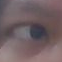

In [ ]:
import cv2
import torch
from torchvision import transforms
from PIL import Image
import numpy as np

# 1. Load Haar Cascade untuk deteksi mata (bawaan OpenCV)
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_eye.xml')

# 2. Ambil gambar dari webcam (atau ambil dari frame video real-time)
img_path = 'test_webcam.jpg' # Hasil jepretan fungsi capture sebelumnya
frame = cv2.imread(img_path)
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

# 3. Deteksi area mata pada foto webcam
eyes = eye_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

if len(eyes) > 0:
    # Ambil koordinat mata pertama yang terdeteksi
    (ex, ey, ew, eh) = eyes[0]

    # Crop gambar khusus di area mata saja agar mirip dataset aslimu!
    eye_crop = frame[ey:ey+eh, ex:ex+ew]

    # Konversi OpenCV (BGR) ke PIL Image (RGB)
    image = Image.fromarray(cv2.cvtColor(eye_crop, cv2.COLOR_BGR2RGB))

    # Transformasi untuk model
    predict_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    input_tensor = predict_transform(image).unsqueeze(0).to(device)

    # Load model & prediksi
    model_name = 'efficientnet_b0'
    model = get_model(model_name, num_classes=5).to(device)
    model.load_state_dict(torch.load(os.path.join("/content/drive/MyDrive/semRAUT/saved_models", f"{model_name}_best.pth")))
    model.eval()

    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)
        confidence, predicted_idx = torch.max(probabilities, 1)

    class_names = ['center', 'down', 'left', 'right', 'up']
    print(f"Berhasil mendeteksi mata!")
    print(f"Prediksi Arah Mata: {class_names[predicted_idx.item()].upper()} (Conf: {confidence.item() * 100:.2f}%)")

    # Tampilkan hasil crop mata yang dibaca model
    display(image)
else:
    print("Mata tidak terdeteksi oleh sistem otomatis. Pastikan posisi wajah menghadap lurus ke cahaya.")

In [ ]:
# import torch
# from torchvision import transforms
# from PIL import Image

# # 1. Load gambar hasil jepretan webcam
# img_path = 'test_webcam.jpg'
# image = Image.open(img_path).convert('RGB')

# # 2. Gunakan transform yang sama dengan validasi/test (Resize ke 224x224 & Normalisasi)
# predict_transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor(),
#     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
# ])

# input_tensor = predict_transform(image).unsqueeze(0).to(device) # Tambah dimensi batch

# # 3. Load model terbaik (misal: efficientnet_b0)
# model_name = 'efficientnet_b0' # Ganti jika pakai resnet18, dll
# num_classes = 5 # Sesuai jumlah kelas kamu (center, down, left, right, up)

# # Inisialisasi arsitektur dan load bobot yang sudah disimpan
# model = get_model(model_name, num_classes).to(device)
# model.load_state_dict(torch.load(os.path.join("/content/drive/MyDrive/semRAUT/saved_models", f"{model_name}_best.pth")))
# model.eval()

# # 4. Lakukan Prediksi
# with torch.no_grad():
#     outputs = model(input_tensor)
#     probabilities = torch.nn.functional.softmax(outputs, dim=1)
#     confidence, predicted_idx = torch.max(probabilities, 1)

# # Daftar nama kelas (pastikan urutannya sesuai dengan train_dataset.classes jika ada)
# # Jika ImageFolder, urutan kelas diurutkan secara alfabetis: ['center', 'down', 'left', 'right', 'up']
# class_names = ['center', 'down', 'left', 'right', 'up']
# predicted_class = class_names[predicted_idx.item()]

# # 5. Tampilkan Hasil
# display(image)
# print(f"\n=== HASIL PREDIKSI WEBCAM ===")
# print(f"Prediksi Arah Mata/Kepala : {predicted_class.upper()}")
# print(f"Tingkat Kepercayaan (Conf): {confidence.item() * 100:.2f}%")